<a href="https://colab.research.google.com/github/Premraj-3390/Leukimia_Blood_classification/blob/main/Leukemia_Simple_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Leukemia Cell Classification with CNN

**Goal:** classify images into two groups: `Benign` and `Malignant`.

The three malignant dataset folders are combined into one label. Run the cells **from top to bottom**. This notebook computes metrics from the actual test run; it does not assume or invent results.

> **Dataset note:** Kaggle credentials are needed to download the dataset. Never share your `kaggle.json` file.

## 1. Import libraries



In [ ]:
import os
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.21.0
GPU available: False


## 2. Install Kaggle CLI

In [ ]:
%pip -q install kaggle


## 3. Upload Kaggle API credentials

In [ ]:
from google.colab import files

uploaded = files.upload()  # Choose your kaggle.json file

if "kaggle.json" not in uploaded:
    raise FileNotFoundError(
        "Please upload the file named kaggle.json from Kaggle Account Settings."
    )

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("/content/kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle credentials configured.")


Saving kaggle.json to kaggle.json
Kaggle credentials configured.


## 4. Download and extract the dataset

In [ ]:
!kaggle datasets download -d mohammadamireshraghi/blood-cell-cancer-all-4class -p /content --unzip
print("Download/extraction command finished.")


Dataset URL: https://www.kaggle.com/datasets/mohammadamireshraghi/blood-cell-cancer-all-4class
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
100% 1.68G/1.68G [00:09<00:00, 200MB/s]

Download/extraction command finished.


## 5. Locate the four-class dataset folder

In [ ]:
EXPECTED_FOLDERS = {
    "Benign",
    "[Malignant] early Pre-B",
    "[Malignant] Pre-B",
    "[Malignant] Pro-B"
}

matches = []
for root, dirs, files in os.walk("/content"):
    if EXPECTED_FOLDERS.issubset(set(dirs)):
        matches.append(root)
    # Skip irrelevant large directories
    dirs[:] = [d for d in dirs if d not in {".cache", "node_modules", ".git"}]

if not matches:
    raise FileNotFoundError(
        "Could not find the dataset folder containing all four class folders. "
        "Check the Kaggle download output and confirm the dataset was extracted."
    )

DATASET_DIR = matches[0]
print("Dataset found:", DATASET_DIR)
print("Class folders:", sorted(os.listdir(DATASET_DIR)))


Dataset found: /content/Blood cell Cancer [ALL]
Class folders: ['Benign', '[Malignant] Pre-B', '[Malignant] Pro-B', '[Malignant] early Pre-B']


## 6. Load images and create binary labels

In [ ]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
records = []

for path in Path(DATASET_DIR).rglob("*"):
    if not path.is_file() or path.suffix.lower() not in image_extensions:
        continue

    folder = path.parent.name
    if folder == "Benign":
        label = "Benign"
    elif folder in {
        "[Malignant] early Pre-B",
        "[Malignant] Pre-B",
        "[Malignant] Pro-B"
    }:
        label = "Malignant"
    else:
        continue

    records.append({"filepath": str(path), "label": label})

df = pd.DataFrame(records)
if df.empty:
    raise ValueError(
        "No labeled images were found. Confirm the four class folder names and dataset path."
    )

print("Total labeled images:", len(df))
print("\nImages per class:")
print(df["label"].value_counts())


Total labeled images: 3242

Images per class:
label
Malignant    2730
Benign        512
Name: count, dtype: int64


## 7. Split into training, validation, and test sets

In [ ]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print(f"Training images:   {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Validation images: {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test images:       {len(test_df)} ({len(test_df)/len(df):.1%})")


Training images:   2269 (70.0%)
Validation images: 486 (15.0%)
Test images:       487 (15.0%)


## 8. Create image generators

In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
CLASS_NAMES = ["Benign", "Malignant"]

train_datagen = ImageDataGenerator(rescale=1.0 / 255.0)
eval_datagen = ImageDataGenerator(rescale=1.0 / 255.0)

train_data = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    classes=CLASS_NAMES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_data = eval_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    classes=CLASS_NAMES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_data = eval_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    classes=CLASS_NAMES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Class indices:", train_data.class_indices)


Found 2269 validated image filenames belonging to 2 classes.
Found 486 validated image filenames belonging to 2 classes.
Found 487 validated image filenames belonging to 2 classes.
Class indices: {'Benign': 0, 'Malignant': 1}


## 9. Build and compile the CNN

In [ ]:
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

    layers.Conv2D(32, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation="relu", padding="same"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,634 (397.01 KB)

 Trainable params: 101,634 (397.01 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Train the model

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    callbacks=[early_stopping]
)


Epoch 1/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.8347 - loss: 0.4705 - val_accuracy: 0.8416 - val_loss: 0.4379
Epoch 2/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.8422 - loss: 0.4381 - val_accuracy: 0.8416 - val_loss: 0.4957
Epoch 3/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.8422 - loss: 0.4418 - val_accuracy: 0.8416 - val_loss: 0.4232
Epoch 4/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.8422 - loss: 0.4298 - val_accuracy: 0.8416 - val_loss: 0.4050
Epoch 5/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.8563 - loss: 0.3645 - val_accuracy: 0.8663 - val_loss: 0.3044


## 11. Evaluate once on the held-out test set

16/16 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.8891 - loss: 0.3197
Test loss: 0.3197
Test accuracy: 0.8891 (88.91%)
16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 715ms/step

Classification report:
              precision    recall  f1-score   support

      Benign     0.7255    0.4805    0.5781        77
   Malignant     0.9083    0.9659    0.9362       410

    accuracy                         0.8891       487
   macro avg     0.8169    0.7232    0.7571       487
weighted avg     0.8794    0.8891    0.8796       487



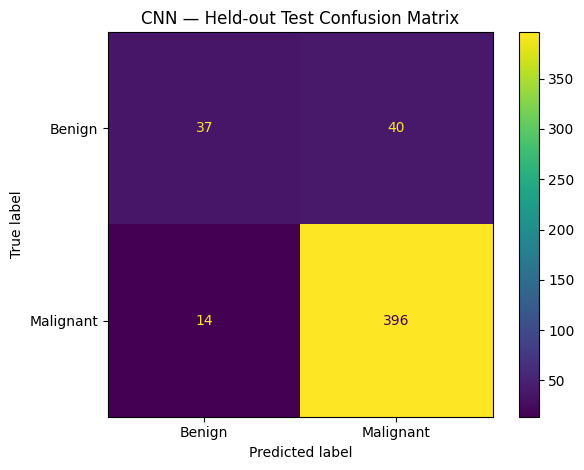

In [ ]:
test_data.reset()
test_loss, test_accuracy = model.evaluate(test_data, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")

test_data.reset()
probabilities = model.predict(test_data, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = test_data.classes

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(values_format="d")
plt.title("CNN — Held-out Test Confusion Matrix")
plt.tight_layout()
plt.show()


## 12. Plot training and validation curves

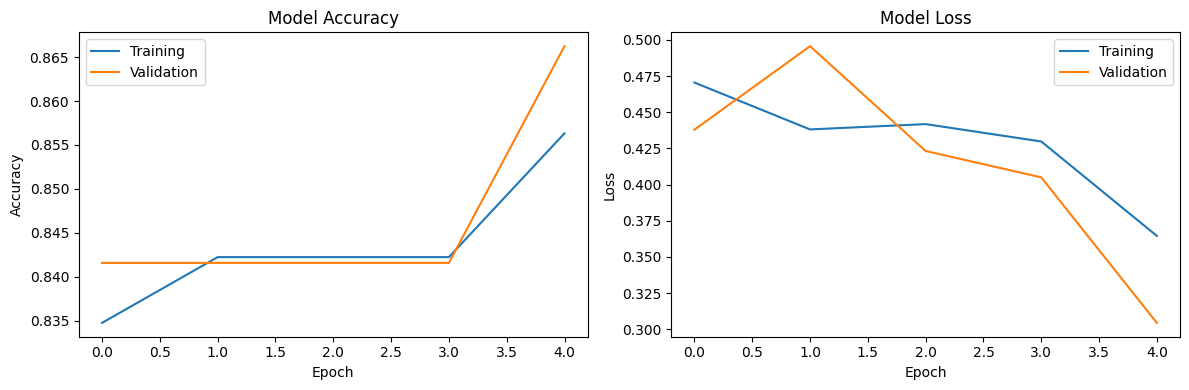

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


## 13. Save the trained model

In [ ]:
MODEL_PATH = "/content/leukemia_cnn.keras"
model.save(MODEL_PATH)
print("Model saved to:", MODEL_PATH)


Model saved to: /content/leukemia_cnn.keras


## Notes for your report

- This is a **binary image-classification experiment**: Benign versus Malignant.
- Accuracy and other metrics must be copied from the completed evaluation cell, not estimated.
- This educational model is not a clinically validated diagnostic tool.
- The split is image-level. If multiple images come from the same patient or slide, a patient/slide-level split is preferable to reduce data leakage.